# The BFGS and L-BFGS Methods

**Course:** Advanced Numerical Optimization (20.IDI16) · **Mentor:** Prof. Marko Miladinović · **Author:** Elvir Muslić

The code half of the seminar paper: our own gradient descent, BFGS and L-BFGS, the checks of the theory, and every number, table and figure of Sections 2.3, 3.2 and 5, with SciPy only as a check. Run it from this folder with `.venv/bin/jupyter nbconvert --to notebook --execute --inplace bfgs_project.ipynb`.

## Part 0. Setup
One BLAS thread, set before NumPy is imported, so that the timings of Section 5.3 compare methods rather than cores. Then the imports, the plot style (8 pt text, figures as wide as the paper's text), the memory $m = 5$ of L-BFGS, one color and one marker per method, and `check`, which prints one line for each check of the theory.

In [1]:
import os

# single-threaded BLAS, set before NumPy loads
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[var] = "1"

import logging
import platform
import time
from collections import deque
from types import SimpleNamespace

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import scipy.optimize

%config InlineBackend.figure_format = "retina"

START = time.perf_counter()
os.makedirs("figures", exist_ok=True)
# fontTools would warn about the old timestamps of the Computer Modern fonts that the PDFs embed
logging.getLogger("fontTools").setLevel(logging.ERROR)
TEXTWIDTH = 360 / 72.27                                         # the paper's text width in inches
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "mathtext.fontset": "cm", "lines.linewidth": 1.0,
    "axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.6, "pdf.fonttype": 42,
    "figure.constrained_layout.use": True})
M = 5                                                           # the memory m of L-BFGS
METHODS = ("gd", "bfgs", "lbfgs")
LABEL = {"gd": "gradient descent", "bfgs": "BFGS", "lbfgs": f"L-BFGS (m = {M})"}   # printed tables
LEGEND = {**LABEL, "lbfgs": f"L-BFGS ($m = {M}$)"}               # figure legends
COLOR = {"gd": "0.5", "bfgs": "C0", "lbfgs": "C1"}               # grey, blue, orange
MARKER = {"gd": "^--", "bfgs": "o-", "lbfgs": "s-"}              # shapes and dashes for grayscale


def check(ok, message):
    """A check of the theory: one line when it holds, an error when it does not."""
    assert ok, f"check failed: {message}"
    print(f"check passed: {message}")


print(f"Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}, "
      f"Matplotlib {matplotlib.__version__}, {platform.system()} {platform.machine()}")

Python 3.14.1, NumPy 2.5.0, SciPy 1.18.1, Matplotlib 3.11.0, Darwin arm64


## Part 1. Methods (Sections 2 and 3)
Our implementation of Sections 2 and 3 in four cells: the line search, the updates, the driver and the test functions.

### The line search: Algorithm 2
Algorithm 2 with $c_1 = 10^{-4}$ and $c_2 = 0.9$: it doubles the trial step until it brackets an acceptable step (lines 1–6), then shrinks the bracket by cubic or quadratic interpolation, with bisection as a safeguard (lines 7–14). The step it returns satisfies the sufficient decrease condition (2.2) and the strong curvature condition (2.3); the gradient is evaluated only where (2.2) holds. After $60$ trials, or when the bracket has shrunk to rounding level, it returns the best step found that satisfies (2.2), or $0$ if there is none (Section 2.4). The comments name the lines of Algorithm 2 that each branch carries out.

In [2]:
C1, C2 = 1e-4, 0.9                                              # the constants of (2.2) and (2.3)


def zoom_trial(a_lo, f_lo, d_lo, a_hi, f_hi, d_hi):
    """Lines 9-10 of Algorithm 2: the minimizer of the cubic (both slopes known) or quadratic
    interpolant of phi on the bracket, or its midpoint if that is not in the middle 80%."""
    with np.errstate(all="ignore"):                             # a failed fit gives inf or nan
        h, t = np.float64(a_hi - a_lo), np.nan
        if d_hi is not None:                                    # cubic: phi and phi' at both ends
            e = d_lo + d_hi - 3 * (f_hi - f_lo) / h
            q = np.sign(h) * np.sqrt(e * e - d_lo * d_hi)
            t = a_hi - h * (d_hi + q - e) / (d_hi - d_lo + 2 * q)
        if not np.isfinite(t):                                  # quadratic: f_lo, d_lo and f_hi
            t = a_lo - d_lo / (2 * ((f_hi - f_lo - d_lo * h) / (h * h)))
    mid = (a_lo + a_hi) / 2                                     # line 10: bisection
    return float(t) if abs(t - mid) <= 0.4 * abs(h) else mid


def line_search(fun, jac, x, p, f0, g0, a):
    """Algorithm 2 from the first trial step a: returns a step, f and the gradient there;
    a = 0 means that no step satisfying (2.2) was found."""
    d0 = float(g0 @ p)                                          # phi'(0) = g_k^T p_k < 0
    # a_lo: the best step with (2.2) so far, alpha_prev of line 1 while bracketing; a_hi: the other
    # end of the bracket, None until there is one; f and d hold phi and phi' there, g the gradient
    a_lo, f_lo, d_lo, g_lo = 0.0, f0, d0, g0
    a_hi = f_hi = d_hi = None
    for _ in range(60):
        if a_hi is not None:                                    # zoom, lines 7-14
            if abs(a_hi - a_lo) <= 1e-16 * max(1.0, a_lo):      # the bracket is at rounding level
                break
            a = zoom_trial(a_lo, f_lo, d_lo, a_hi, f_hi, d_hi)
        fa = fun(x + a * p)
        # lines 3 and 11: (2.2) fails at a, or f does not fall below its value at a_lo
        if not fa <= f0 + C1 * a * d0 or fa >= f_lo:
            a_hi, f_hi, d_hi = a, fa, None
            continue
        ga = jac(x + a * p)
        da = float(ga @ p)
        if abs(da) <= -C2 * d0:                                 # lines 4 and 12: (2.3) holds too
            return a, fa, ga
        # lines 5 and 13: the slope at a points back to a_lo, so a and a_lo bracket a step
        points_back = da >= 0 if a_hi is None else da * (a_hi - a_lo) >= 0
        if points_back:
            a_hi, f_hi, d_hi = a_lo, f_lo, d_lo
        a_lo, f_lo, d_lo, g_lo = a, fa, da, ga                  # lines 6, 13 and 14
        if a_hi is None:                                        # line 6: no bracket yet, double a
            a *= 2
    return a_lo, f_lo, g_lo

### The updates and the two-loop recursion: (2.7), (2.8) and Algorithm 3
`bfgs_update` is the product form (2.7), used for the checks; `bfgs_update_rank2` is the rank-two form (2.8), which the solver uses because it costs $O(n^2)$. `two_loop` is Algorithm 3: it applies the $m$ stored updates to a vector, starting from $H_k^0 = \gamma_k I$ with $\gamma_k$ from (3.1).

In [3]:
def bfgs_update(H, s, y):
    """(2.7) in product form: (I - rho s y^T) H (I - rho y s^T) + rho s s^T, rho = 1 / (y^T s)."""
    rho = 1 / (y @ s)
    V = np.eye(len(s)) - rho * np.outer(y, s)
    return V.T @ H @ V + rho * np.outer(s, s)


def bfgs_update_rank2(H, s, y):
    """(2.8): H + s w^T + w s^T with w = rho/2 (1 + rho y^T H y) s - rho H y, in O(n^2) operations;
    overwrites H."""
    rho, Hy = 1 / (y @ s), H @ y
    w = 0.5 * rho * (1 + rho * (y @ Hy)) * s - rho * Hy
    # the outer product s w^T of (2.8), written as a column times a row
    H += s[:, None] @ w[None, :]
    H += w[:, None] @ s[None, :]                                # w s^T
    return H


def two_loop(g, pairs):
    """Algorithm 3: H_k g from the pairs (s_i, y_i, rho_i), oldest first, with H_k^0 = gamma_k I."""
    q, alphas = g.copy(), []
    for s, y, rho in reversed(pairs):                           # first loop: newest pair to oldest
        alphas.append(rho * (s @ q))
        q -= alphas[-1] * y
    s, y, _ = pairs[-1]
    r = (s @ y) / (y @ y) * q                                   # H_k^0 q, gamma_k by (3.1)
    for (s, y, rho), a in zip(pairs, reversed(alphas)):         # second loop: oldest pair to newest
        r += (a - rho * (y @ r)) * s
    return r

### The driver: Algorithm 1 and Section 3.3
`minimize` runs gradient descent ($p_k = -g_k$), BFGS (Algorithm 1) or L-BFGS (Section 3.3) until the stopping test (2.9), $\|g_k\| \le \varepsilon \|g_0\|$ with $\varepsilon = 10^{-6}$ by default, or for at most $10^4$ iterations. Its rules:
- **First trial step:** $\min(1, 1/\|g_0\|)$ at $k = 0$; later $1$ for BFGS and L-BFGS, and $\alpha_{k-1} g_{k-1}^\top p_{k-1} / g_k^\top p_k$ for gradient descent.
- **Scaling:** before the first update, $H_k$ is replaced by $(y_k^\top s_k / y_k^\top y_k)\, I$ (line 7 of Algorithm 1).
- **Safeguards:** a pair with $s_k^\top y_k \le 10^{-12} \|s_k\| \|y_k\|$ is skipped, and a direction that is not a descent direction is replaced by $-g_k$, which also drops $H_k$ or the pairs.
- **Status:** `"converged"` when (2.9) holds, `"cap"` after `max_iter` iterations, and `"stalled"` when the line search finds no step that satisfies (2.2).

In [4]:
def minimize(f, grad, x0, method="bfgs", m=M, eps=1e-6, max_iter=10_000, keep_x=False):
    """Gradient descent ("gd"), BFGS ("bfgs", Algorithm 1) or L-BFGS with m pairs ("lbfgs",
    Section 3.3) from x0, until the test (2.9), the cap max_iter or a failed line search."""
    t0, count = time.perf_counter(), {"f": 0, "g": 0}

    def fun(x):
        """f, counted; a long trial step may overflow, and (2.2) then rejects it."""
        count["f"] += 1
        with np.errstate(over="ignore", invalid="ignore"):
            return float(f(x))

    def jac(x):
        """The gradient, counted."""
        count["g"] += 1
        return grad(x)

    x = np.array(x0, dtype=float)
    fx, g = fun(x), jac(x)
    r = SimpleNamespace(gnorm=[np.linalg.norm(g)], xs=[x], alpha=[], sy=[], decrease=[],
                        curvature=[], status="cap")
    H, pairs, a0 = None, deque(maxlen=m), min(1.0, 1 / r.gnorm[0])     # a0: the first trial step
    while r.gnorm[-1] > eps * r.gnorm[0] and len(r.sy) < max_iter:   # (2.9)
        # line 3; gradient descent, and the first step of BFGS and L-BFGS, take p = -g
        if method == "bfgs" and H is not None:
            p = -H @ g
        elif method == "lbfgs" and pairs:
            p = -two_loop(g, pairs)
        else:
            p = -g
        if g @ p >= 0:                                          # not a descent direction: restart
            p, H = -g, None
            pairs.clear()
        slope = float(g @ p)
        a, f_new, g_new = line_search(fun, jac, x, p, fx, g, a0)
        if a == 0:                                              # no step satisfies (2.2)
            r.status = "stalled"
            break
        s, y = a * p, g_new - g
        r.alpha.append(a)
        r.sy.append(float(s @ y))
        r.decrease.append((fx - f_new) / (a * -slope))           # (2.2) holds iff this is >= c1
        r.curvature.append(abs(float(g_new @ p)) / -slope)       # (2.3) holds iff this is <= c2
        # the update, unless the pair fails the safeguard s^T y > 1e-12 ||s|| ||y||
        if method != "gd" and r.sy[-1] > 1e-12 * np.linalg.norm(s) * np.linalg.norm(y):
            if method == "lbfgs":
                pairs.append((s, y, 1 / r.sy[-1]))               # the deque drops the oldest pair
            else:
                # lines 7-8: H = (y^T s / y^T y) I before the first update, then (2.8)
                H = bfgs_update_rank2(r.sy[-1] / (y @ y) * np.eye(x.size) if H is None else H, s, y)
        x, fx, g = x + s, f_new, g_new
        r.gnorm.append(np.linalg.norm(g))
        # the next first trial step: 1, or for gradient descent the step that keeps alpha g^T p
        a0 = a * slope / float(g @ -g) if method == "gd" else 1.0
        if keep_x:
            r.xs.append(x)
    if r.gnorm[-1] <= eps * r.gnorm[0]:
        r.status = "converged"
    r.x, r.H, r.iterations, r.nfev, r.ngev = x, H, len(r.sy), count["f"], count["g"]
    r.time = time.perf_counter() - t0
    return r


def check_wolfe(runs):
    """Every accepted step of the runs satisfies (2.2) and (2.3) and has s^T y > 0 (Lemma 2.1)."""
    check(all(min(r.decrease) >= C1 and max(r.curvature) <= C2 and min(r.sy) > 0 for r in runs),
          "every accepted step satisfies sufficient decrease and strong curvature, and s^T y > 0")

### Test functions (Sections 5.1 and 5.2)
The Rosenbrock function $f(x) = 100(x_2 - x_1^2)^2 + (1 - x_1)^2$ from $x_0 = (-1.2, 1)$, and two functions of Vilin, the course's MATLAB framework, from its starting point $x_0 = (1, \dots, 1)$: TRIDIA, $f(x) = (x_1 - 1)^2 + \sum_{i=2}^n i\,(2x_i - x_{i-1})^2$ with minimizer $x^*_i = 2^{1-i}$, and Raydan 1, $f(x) = \sum_{i=1}^n \tfrac{i}{10}\,(e^{x_i} - x_i)$ with $x^* = 0$.

In [5]:
def rosenbrock(x):
    return 100 * (x[1] - x[0] ** 2) ** 2 + (1 - x[0]) ** 2


def rosenbrock_grad(x):
    return np.array([-400 * x[0] * (x[1] - x[0] ** 2) - 2 * (1 - x[0]), 200 * (x[1] - x[0] ** 2)])


def tridia(x):
    i = np.arange(2, x.size + 1)
    return (x[0] - 1) ** 2 + np.sum(i * (2 * x[1:] - x[:-1]) ** 2)


def tridia_grad(x):
    # term i, differentiated in 2 x_i - x_{i-1}; x_i enters term i with 2 and term i + 1 with -1
    r = 2 * np.arange(2, x.size + 1) * (2 * x[1:] - x[:-1])
    return np.r_[2 * (x[0] - 1), 2 * r] - np.r_[r, 0]


def raydan1(x):
    return np.sum(np.arange(1, x.size + 1) / 10 * (np.exp(x) - x))


def raydan1_grad(x):
    return np.arange(1, x.size + 1) / 10 * (np.exp(x) - 1)


PROBLEMS = {"TRIDIA": (tridia, tridia_grad), "Raydan 1": (raydan1, raydan1_grad)}
X_STAR = {"TRIDIA": lambda n: 0.5 ** np.arange(n), "Raydan 1": np.zeros}   # the minimizers

## Part 2. Checks of the theory (Sections 2.3 and 3.2)
### The computed update of Section 2.3
$H_k = I$, $s_k = (1, 0)^\top$ and $y_k = (2, 1)^\top$. Both (2.7) and (2.8) must give $H_{k+1} = \begin{pmatrix} 3/4 & -1/2 \\ -1/2 & 1 \end{pmatrix}$ exactly; it satisfies the secant equation (2.5), and its eigenvalues $(7 \pm \sqrt{17})/8$ are positive (Theorem 2.2).

In [6]:
H, s, y = np.eye(2), np.array([1.0, 0.0]), np.array([2.0, 1.0])
H_product, H_rank2 = bfgs_update(H, s, y), bfgs_update_rank2(H.copy(), s, y)
print("H_k+1 =", H_product.tolist())
print("secant equation: H_k+1 y - s =", (H_product @ y - s).tolist())
print("eigenvalues:", np.linalg.eigvalsh(H_product).round(4).tolist(),
      "and (7 -/+ sqrt(17)) / 8 =", ((7 + np.array([-1, 1]) * np.sqrt(17)) / 8).round(4).tolist())
check(np.array_equal(H_product, [[0.75, -0.5], [-0.5, 1.0]]) and np.array_equal(H_rank2, H_product),
      "both forms give H_k+1 = [[3/4, -1/2], [-1/2, 1]] exactly")

H_k+1 = [[0.75, -0.5], [-0.5, 1.0]]
secant equation: H_k+1 y - s = [0.0, 0.0]
eigenvalues: [0.3596, 1.3904] and (7 -/+ sqrt(17)) / 8 = [0.3596, 1.3904]
check passed: both forms give H_k+1 = [[3/4, -1/2], [-1/2, 1]] exactly


### The two-loop recursion of Section 3.2
Six random pairs in $\mathbb{R}^7$ with $s^\top y > 0$: the direction of Algorithm 3 must equal $H_k g$, where $H_k$ is built explicitly by applying (2.7) six times to $\gamma_k I$.

In [7]:
rng = np.random.default_rng(0)
pairs = []
for _ in range(6):                                              # m = 6 pairs in R^7 with s^T y > 0
    s, y = rng.standard_normal(7), rng.standard_normal(7)
    y = y if s @ y > 0 else -y
    pairs.append((s, y, 1 / (s @ y)))
s, y, _ = pairs[-1]
H = (s @ y) / (y @ y) * np.eye(7)                               # H_k^0 = gamma_k I, (3.1)
for s, y, _ in pairs:                                           # the m updates (2.7), oldest first
    H = bfgs_update(H, s, y)
g = rng.standard_normal(7)
diff = np.linalg.norm(two_loop(g, pairs) - H @ g) / np.linalg.norm(H @ g)
check(diff < 1e-13, f"the two-loop direction equals H_k g, relative difference {diff:.1e}")

check passed: the two-loop direction equals H_k g, relative difference 3.9e-16


## Part 3. Experiments (Sections 5.1–5.3)
The experiments of Sections 5.1, 5.2 and 5.3, with our own code and the stopping test (2.9) with $\varepsilon = 10^{-6}$, unless a cell says otherwise.

### The Rosenbrock function (Section 5.1)
The three methods from $x_0 = (-1.2, 1)$. Every step is checked against (2.2) and (2.3) and for $s_k^\top y_k > 0$ (Lemma 2.1), and the last BFGS matrix is compared with $\nabla^2 f(x^*)^{-1}$.

In [8]:
x0, x_star = np.array([-1.2, 1.0]), np.array([1.0, 1.0])
hess_star = np.array([[802.0, -400.0], [-400.0, 200.0]])        # the Hessian of f at x*
runs = {mt: minimize(rosenbrock, rosenbrock_grad, x0, method=mt, keep_x=True) for mt in METHODS}
print("Rosenbrock, n = 2, eps = 1e-6")
print(f"{'method':17s} {'iterations':>10s} {'f evals':>8s} {'g evals':>8s} {'||x - x*||':>11s}")
for mt, r in runs.items():
    print(f"{LABEL[mt]:17s} {r.iterations:10d} {r.nfev:8d} {r.ngev:8d} "
          f"{np.linalg.norm(r.x - x_star):11.1e}")

print("\nAccepted steps that satisfy each condition, with the extreme value of its ratio:")
print("  sufficient decrease (2.2): (f_k - f_k+1) / (alpha_k |g_k^T p_k|) >= c1 = 1e-4 (smallest)")
print("  strong curvature (2.3):    |g_k+1^T p_k| / |g_k^T p_k| <= c2 = 0.9 (largest)")
print("  curvature condition (2.6): s_k^T y_k > 0 (smallest)")
print(f"{'method':17s} {'steps':>6s} {'decrease':>17s} {'curvature':>16s} {'s^T y > 0':>17s}")
for mt, r in runs.items():
    cells = (f"{sum(d >= C1 for d in r.decrease)} ({min(r.decrease):#.3g})",
             f"{sum(c <= C2 for c in r.curvature)} ({max(r.curvature):#.3g})",
             f"{sum(v > 0 for v in r.sy)} ({min(r.sy):.1e})")
    print(f"{LABEL[mt]:17s} {r.iterations:6d} " + " ".join(f"{c:>17s}" for c in cells))
check_wolfe(runs.values())

print("\nBFGS's last H_k:      ", runs["bfgs"].H.round(4).tolist())
print("inverse Hessian at x*:", np.linalg.inv(hess_star).round(4).tolist())
steps = runs["bfgs"].alpha
unit = next((i for i, a in enumerate(reversed(steps)) if a != 1.0), len(steps))
print(f"BFGS takes the unit step alpha_k = 1 at each of its last {unit} iterations")

Rosenbrock, n = 2, eps = 1e-6
method            iterations  f evals  g evals  ||x - x*||
gradient descent        5508     5683     5607     5.0e-04
BFGS                      38       52       43     3.1e-06
L-BFGS (m = 5)            37       48       41     9.8e-07

Accepted steps that satisfy each condition, with the extreme value of its ratio:
  sufficient decrease (2.2): (f_k - f_k+1) / (alpha_k |g_k^T p_k|) >= c1 = 1e-4 (smallest)
  strong curvature (2.3):    |g_k+1^T p_k| / |g_k^T p_k| <= c2 = 0.9 (largest)
  curvature condition (2.6): s_k^T y_k > 0 (smallest)
method             steps          decrease        curvature         s^T y > 0
gradient descent    5508     5508 (0.0883)      5508 (0.899)    5508 (6.6e-11)
BFGS                  38        38 (0.181)        38 (0.876)      38 (5.5e-09)
L-BFGS (m = 5)        37        37 (0.181)        37 (0.870)      37 (2.4e-09)
check passed: every accepted step satisfies sufficient decrease and strong curvature, and s^T y > 0

BFGS's last 

### Rates of convergence (Section 5.1)
The same three runs with $\varepsilon = 10^{-12}$, for a longer tail, and their error ratios $e_{k+1}/e_k = \|x_{k+1} - x^*\| / \|x_k - x^*\|$. The ratios tend to $0$ when convergence is superlinear (Theorem 4.3) and stay near a constant below $1$ when it is linear; for a quadratic with exact line searches, Theorem 4.1 gives the constant $(\kappa - 1)/(\kappa + 1)$, with $\kappa$ the condition number of the Hessian, here $\nabla^2 f(x^*)$. For gradient descent, the geometric mean of the last $1000$ ratios is compared with it.

In [9]:
tight = {mt: minimize(rosenbrock, rosenbrock_grad, x0, method=mt, eps=1e-12, max_iter=50_000,
                      keep_x=True) for mt in METHODS}
ratios = {}
lines = ["Rosenbrock, eps = 1e-12",
         f"{'method':17s} {'iterations':>10s}  {'status':9s}  {'last 4 ratios':36s}  "
         "geometric mean"]
for mt, r in tight.items():
    err = np.linalg.norm(np.array(r.xs) - x_star, axis=1)
    ratios[mt] = err[1:] / err[:-1]                             # ratios[mt][k] = e_k+1 / e_k
    last = ratios[mt][-4:]
    lines.append(f"{LABEL[mt]:17s} {r.iterations:10d}  {r.status:9s}  "
                 f"{str(last.round(5).tolist()):36s}  {np.exp(np.log(last).mean()):.4f}")
kappa = np.linalg.cond(hess_star)
lines += [f"gradient descent, geometric mean of the last 1000 ratios: "
          f"{np.exp(np.log(ratios['gd'][-1000:]).mean()):.4f}",
          f"kappa = {kappa:.0f}, (kappa - 1) / (kappa + 1) = {(kappa - 1) / (kappa + 1):.4f}"]
print("\n".join(lines))

Rosenbrock, eps = 1e-12
method            iterations  status     last 4 ratios                         geometric mean
gradient descent       18168  converged  [0.99829, 0.99944, 0.99852, 0.99951]  0.9989
BFGS                      40  converged  [0.13354, 0.02729, 0.00013, 0.01718]  0.0095
L-BFGS (m = 5)            40  converged  [0.01377, 0.00467, 0.22062, 0.00294]  0.0143
gradient descent, geometric mean of the last 1000 ratios: 0.9990
kappa = 2508, (kappa - 1) / (kappa + 1) = 0.9992


### Figures 1 and 2: paths and error ratios
Figure 1 shows the iterates over the contours of $f$ ($\varepsilon = 10^{-6}$): (a) every iterate of BFGS, (b) a marker at every 100th iterate of gradient descent. Figure 2 shows the error ratios ($\varepsilon = 10^{-12}$), the ratio $e_{k+1}/e_k$ at iteration $k$: (a) BFGS and L-BFGS; (b) gradient descent, each ratio in light grey, the geometric mean of the preceding $1000$ ratios solid, and $(\kappa - 1)/(\kappa + 1)$ dashed.

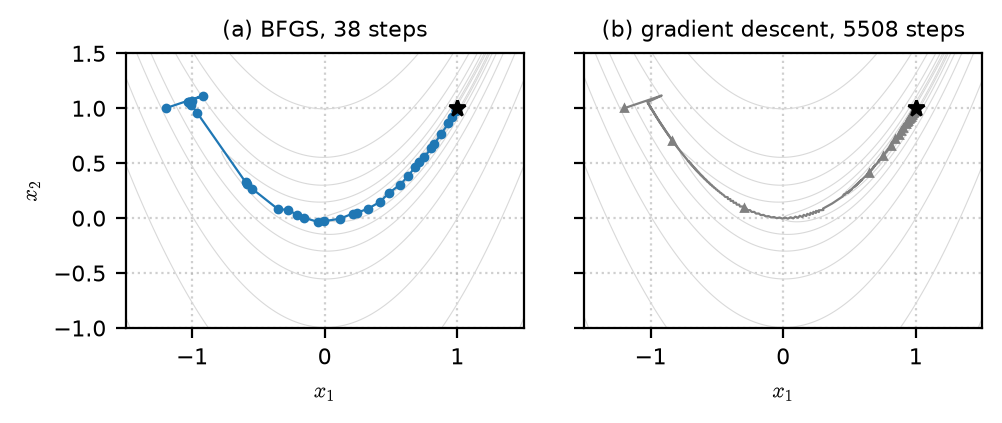

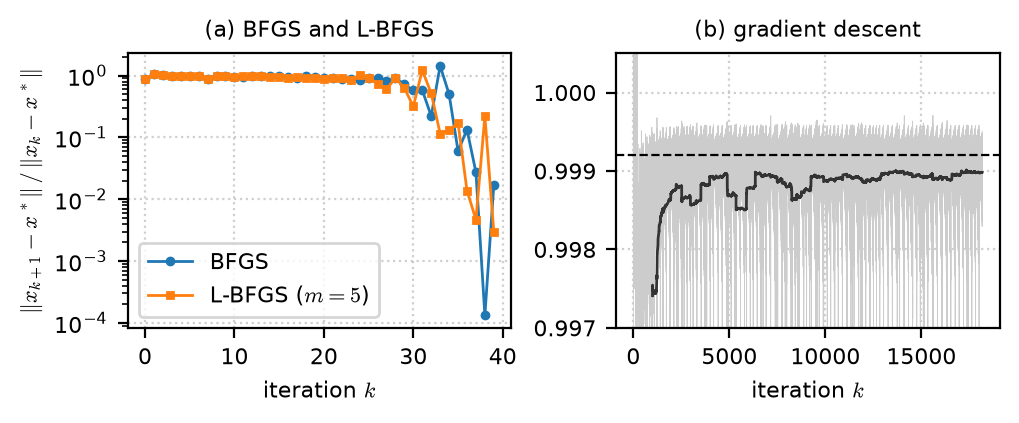

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.0), sharex=True, sharey=True)
x1, x2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.0, 1.5, 300))
for ax, mt, every, tag in zip(axes, ("bfgs", "gd"), (1, 100), "ab"):
    ax.contour(x1, x2, rosenbrock(np.array([x1, x2])), levels=np.logspace(-1, 3, 9), colors="0.85",
               linewidths=0.4)
    X = np.array(runs[mt].xs)
    ax.plot(X[:, 0], X[:, 1], "-", color=COLOR[mt], lw=0.8)
    ax.plot(X[::every, 0], X[::every, 1], MARKER[mt][0], color=COLOR[mt], ms=2.5)
    ax.plot(*x_star, "k*", ms=6)
    ax.set(title=f"({tag}) {LABEL[mt]}, {runs[mt].iterations} steps", xlabel="$x_1$")
axes[0].set_ylabel("$x_2$")
fig.savefig("figures/rosenbrock_path.pdf")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.0))
# (a) superlinear convergence: the ratios fall toward 0
for mt in ("bfgs", "lbfgs"):
    ax1.semilogy(np.arange(len(ratios[mt])), ratios[mt], MARKER[mt], color=COLOR[mt], ms=2.5,
                 label=LEGEND[mt])
ax1.set(xlabel="iteration $k$", ylabel=r"$\|x_{k+1} - x^*\| \,/\, \|x_k - x^*\|$",
        title="(a) BFGS and L-BFGS")
ax1.legend(loc="lower left")
# (b) linear convergence: the ratios stay near a constant
q = ratios["gd"]
ax2.plot(np.arange(len(q)), q, color="0.8", lw=0.3)
ax2.plot(np.arange(999, len(q)), np.exp(np.convolve(np.log(q), np.ones(1000) / 1000, mode="valid")),
         color="0.2")
ax2.axhline((kappa - 1) / (kappa + 1), color="k", ls="--", lw=0.8)
ax2.set(xlabel="iteration $k$", ylim=(0.997, 1.0005), xticks=range(0, len(q) + 1, 5000),
        title="(b) gradient descent")
fig.savefig("figures/rosenbrock_rates.pdf")
plt.show()

### TRIDIA and Raydan 1, $n = 100$: Table 1 (Section 5.2)
The iterations, the evaluations of $f$ and $\nabla f$, and the final $\|g_k\| / \|g_0\|$ of the three methods. Every accepted step is checked against (2.2) and (2.3), as for the Rosenbrock function.

In [11]:
lines = ["n = 100, x0 = (1, ..., 1), eps = 1e-6",
         f"{'function':9s} {'method':17s} {'iterations':>10s} {'f evals':>8s} {'g evals':>8s} "
         f"{'||g||/||g0||':>13s}"]
table = []
for name, (f, grad) in PROBLEMS.items():
    for mt in METHODS:
        r = minimize(f, grad, np.ones(100), method=mt)
        table.append(r)
        lines.append(f"{name:9s} {LABEL[mt]:17s} {r.iterations:10d} {r.nfev:8d} {r.ngev:8d} "
                     f"{r.gnorm[-1] / r.gnorm[0]:13.1e}")
print("\n".join(lines))
check_wolfe(table)

n = 100, x0 = (1, ..., 1), eps = 1e-6
function  method            iterations  f evals  g evals  ||g||/||g0||
TRIDIA    gradient descent        2547     2655     2605       9.9e-07
TRIDIA    BFGS                      73       79       75       6.5e-07
TRIDIA    L-BFGS (m = 5)           135      138      137       9.2e-07
Raydan 1  gradient descent         220      250      229       9.9e-07
Raydan 1  BFGS                      92       93       93       9.2e-07
Raydan 1  L-BFGS (m = 5)            55       58       57       8.9e-07
check passed: every accepted step satisfies sufficient decrease and strong curvature, and s^T y > 0


### Larger $n$: Table 2 (Section 5.3)
Gradient descent up to $n = 10^5$ with a cap of $10^4$ iterations, L-BFGS up to $n = 10^6$, and BFGS only at $n = 10^3$, since a dense $H_k$ needs $8n^2$ bytes. A run that ends at the cap is marked `cap`, and its final $\|g_k\| / \|g_0\|$ is printed below the table. Every accepted step is checked against (2.2) and (2.3).

In [12]:
def in_units(b):
    """b bytes in TB, GB, MB or kB."""
    units = ((1e12, "TB"), (1e9, "GB"), (1e6, "MB"), (1e3, "kB"))
    return next(f"{b / u:g} {unit}" for u, unit in units if b >= u)


SIZES = {"gd": (10**3, 10**4, 10**5), "bfgs": (10**3,), "lbfgs": (10**3, 10**4, 10**5, 10**6)}
ALL_N = SIZES["lbfgs"]
lines = [f"{'memory':26s}" + "".join(f"{f'n = {n}':>14s}" for n in ALL_N)]
for what, nbytes in (("dense H_k, 8 n^2 bytes", lambda n: 8 * n * n),
                     ("L-BFGS pairs, 16 m n bytes", lambda n: 16 * M * n)):
    lines.append(f"{what:26s}" + "".join(f"{in_units(nbytes(n)):>14s}" for n in ALL_N))
lines += ["", f"{'function':9s} {'method':17s} {'n':>8s}  {'iterations':>10s} {'time (s)':>9s}"]
large, capped = [], []
for name, (f, grad) in PROBLEMS.items():
    for mt in METHODS:
        for n in SIZES[mt]:
            r = minimize(f, grad, np.ones(n), method=mt)
            large.append(r)
            result = r.iterations if r.status == "converged" else r.status
            lines.append(f"{name:9s} {LABEL[mt]:17s} {n:8d}  {result:>10} {r.time:#9.3g}")
            if r.status == "cap":
                capped.append(f"  {LABEL[mt]}, {name}, n = {n}: {r.gnorm[-1] / r.gnorm[0]:.1e}")
lines += ["cap = stopped at the cap of 10^4 iterations, where ||g||/||g0|| is"] + capped
print("\n".join(lines))
check_wolfe(large)

memory                          n = 1000     n = 10000    n = 100000   n = 1000000
dense H_k, 8 n^2 bytes              8 MB        800 MB         80 GB          8 TB
L-BFGS pairs, 16 m n bytes         80 kB        800 kB          8 MB         80 MB

function  method                   n  iterations  time (s)
TRIDIA    gradient descent      1000         cap     0.311
TRIDIA    gradient descent     10000         cap     0.813
TRIDIA    gradient descent    100000         cap      4.72
TRIDIA    BFGS                  1000         241     0.505
TRIDIA    L-BFGS (m = 5)        1000         354    0.0200
TRIDIA    L-BFGS (m = 5)       10000         862     0.128
TRIDIA    L-BFGS (m = 5)      100000        1068     0.934
TRIDIA    L-BFGS (m = 5)     1000000        1104      9.60
Raydan 1  gradient descent      1000         983    0.0284
Raydan 1  gradient descent     10000        1985     0.205
Raydan 1  gradient descent    100000        2159      1.95
Raydan 1  BFGS                  1000      

### Figure 3: time per iteration (Section 5.3)
Time per iteration against $n$: the fastest of five runs of 30 iterations on TRIDIA, for BFGS at $n = 250, \dots, 4000$ and for L-BFGS and gradient descent at $n = 10^3, \dots, 10^6$, in milliseconds. Each slope is fitted to the three largest $n$ of its method, where the work of an iteration outweighs its fixed cost in Python; the dashed lines of slopes 1 and 2 are drawn for comparison.

method            slope  ms per iteration at n = ...
gradient descent   0.90  1000: 0.0348, 10000: 0.0914, 100000: 0.555, 1000000: 5.64
BFGS               2.00  250: 0.168, 500: 0.548, 1000: 2.09, 2000: 8.41, 4000: 33.5
L-BFGS (m = 5)     0.89  1000: 0.0577, 10000: 0.153, 100000: 0.919, 1000000: 9.15


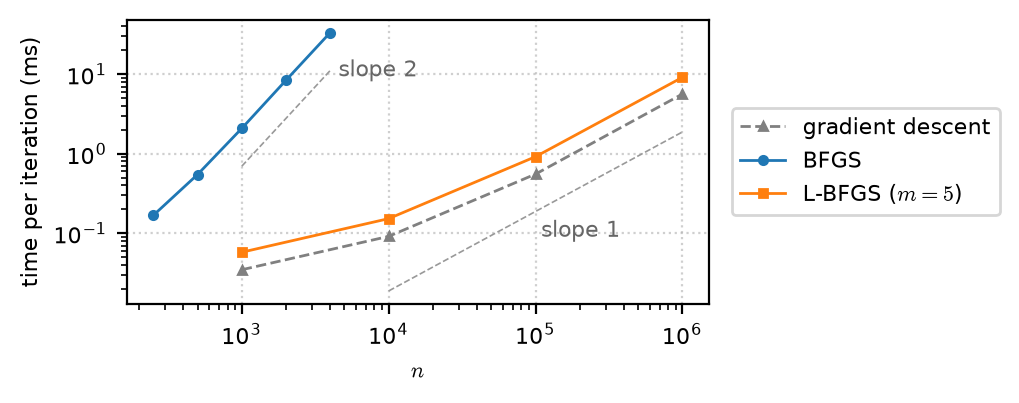

In [13]:
def time_per_iteration(n, method):
    """The fastest of five runs of 30 iterations on TRIDIA; with eps = 0 no run stops early."""
    times = []
    for _ in range(5):
        r = minimize(tridia, tridia_grad, np.ones(n), method=method, eps=0, max_iter=30)
        times.append(r.time / r.iterations)
    return min(times)


GRID = {"gd": (10**3, 10**4, 10**5, 10**6), "bfgs": (250, 500, 1000, 2000, 4000),
        "lbfgs": (10**3, 10**4, 10**5, 10**6)}
per_iteration, lines = {}, [f"{'method':17s} {'slope':>5s}  ms per iteration at n = ..."]
for mt in METHODS:
    per_iteration[mt] = 1e3 * np.array([time_per_iteration(n, mt) for n in GRID[mt]])   # in ms
    slope = np.polyfit(np.log(GRID[mt][-3:]), np.log(per_iteration[mt][-3:]), 1)[0]
    lines.append(f"{LABEL[mt]:17s} {slope:5.2f}  "
                 + ", ".join(f"{n}: {t:#.3g}" for n, t in zip(GRID[mt], per_iteration[mt])))
print("\n".join(lines))

fig, ax = plt.subplots(figsize=(TEXTWIDTH, 1.9))
for mt in METHODS:
    ax.loglog(GRID[mt], per_iteration[mt], MARKER[mt], color=COLOR[mt], ms=3, label=LEGEND[mt])
# reference lines of slopes 1 and 2, a factor 3 below the data of gradient descent and BFGS
n1, n2 = np.array([1e4, 1e6]), np.array([1e3, 4e3])
t1 = per_iteration["gd"][-1] / 3 * n1 / n1[-1]
t2 = per_iteration["bfgs"][-1] / 3 * (n2 / n2[-1]) ** 2
ax.loglog(n1, t1, "--", color="0.6", lw=0.6)
ax.loglog(n2, t2, "--", color="0.6", lw=0.6)
ax.annotate("slope 1", (1e5, t1[-1] / 10), xytext=(2, -3), textcoords="offset points",
            ha="left", va="top", color="0.4")                   # below the middle of its line
ax.annotate("slope 2", (n2[-1], t2[-1]), xytext=(3, 0), textcoords="offset points",
            ha="left", va="center", color="0.4")                # right of its upper end
ax.set(xlabel="$n$", ylabel="time per iteration (ms)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.savefig("figures/scaling.pdf")
plt.show()

## Part 4. Checks against SciPy (Section 5.4)
Table 3 of Section 5.4. (a) SciPy's BFGS keeps only its last $H_k$; our (2.7), applied along all but its last step from $H_0 = I$ (SciPy does not scale $H_0$, and does not update after the step that meets its test), must give the same matrix. (b) and (c) compare our BFGS and L-BFGS with SciPy's BFGS and L-BFGS-B ($m = 5$) under the stopping test (2.9); L-BFGS-B applies it in the max norm, with its test on the decrease of $f$ switched off (`ftol = 0`). Each SciPy BFGS run must end with success, and each L-BFGS-B run by its gradient test.

In [14]:
xs = [x0]
# SciPy's line search uses c1 = 1e-4 and c2 = 0.9 by default, our C1 and C2
res = scipy.optimize.minimize(rosenbrock, x0, jac=rosenbrock_grad, method="BFGS",
                              callback=lambda xk: xs.append(xk), options={"gtol": 1e-5, "norm": 2})
H = np.eye(2)                                                   # SciPy's H_0 = I
for xa, xb in zip(xs[:-2], xs[1:-1]):                           # all but SciPy's last step
    H = bfgs_update(H, xb - xa, rosenbrock_grad(xb) - rosenbrock_grad(xa))
diff_H = np.linalg.norm(H - res.hess_inv) / np.linalg.norm(res.hess_inv)
lines = [f"(a) SciPy BFGS on Rosenbrock, gtol = 1e-5: {res.nit} iterations. (2.7) along all but "
         "its last step,",
         f"    from H_0 = I, gives res.hess_inv to a relative difference of {diff_H:.1e} "
         "(Frobenius norm)",
         "", f"{'':4s}{'function':9s} {'n':>5s} {'iterations: ours':>17s} {'SciPy':>6s} "
         f"{'||x_ours - x_SciPy||_inf':>25s} {'||x_ours - x*||_inf':>20s}"]
gaps, ended = [], []
for part, n, mt, sp_method in (("(b)", 100, "bfgs", "BFGS"), ("(c)", 1000, "lbfgs", "L-BFGS-B")):
    for name, (f, grad) in PROBLEMS.items():
        g0 = grad(np.ones(n))
        # (2.9); L-BFGS-B tests the max norm; ftol = 0 switches off its test on the decrease of f
        options = ({"gtol": 1e-6 * np.linalg.norm(g0), "norm": 2} if sp_method == "BFGS"
                   else {"maxcor": M, "gtol": 1e-6 * np.abs(g0).max(), "ftol": 0})
        sp = scipy.optimize.minimize(f, np.ones(n), jac=grad, method=sp_method, options=options)
        ours = minimize(f, grad, np.ones(n), method=mt)
        gaps.append(np.abs(ours.x - sp.x).max())
        ended.append(sp.success if sp_method == "BFGS" else "PGTOL" in sp.message)
        lines.append(f"{part:4s}{name:9s} {n:5d} {ours.iterations:17d} {sp.nit:6d} "
                     f"{gaps[-1]:25.1e} {np.abs(ours.x - X_STAR[name](n)).max():20.1e}")
lines.append("(b) our BFGS against SciPy's BFGS, (c) our L-BFGS against SciPy's L-BFGS-B")
print("\n".join(lines))
check(diff_H < 1e-10 and all(ended) and max(gaps) < 1e-2,
      f"SciPy agrees: H_k to {diff_H:.0e}; all four runs end by their tests, "
      f"within {max(gaps):.0e} of our x")
print(f"\nrun time of the whole notebook: {time.perf_counter() - START:.0f} s")

(a) SciPy BFGS on Rosenbrock, gtol = 1e-5: 32 iterations. (2.7) along all but its last step,
    from H_0 = I, gives res.hess_inv to a relative difference of 3.0e-13 (Frobenius norm)

    function      n  iterations: ours  SciPy  ||x_ours - x_SciPy||_inf  ||x_ours - x*||_inf
(b) TRIDIA      100                73    109                   6.0e-05              3.7e-06
(b) Raydan 1    100                92     53                   6.2e-05              4.6e-05
(c) TRIDIA     1000               354    335                   3.7e-03              7.6e-04
(c) Raydan 1   1000               121    136                   1.1e-03              1.3e-03
(b) our BFGS against SciPy's BFGS, (c) our L-BFGS against SciPy's L-BFGS-B
check passed: SciPy agrees: H_k to 3e-13; all four runs end by their tests, within 4e-03 of our x

run time of the whole notebook: 34 s
